In [1]:
import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from ipywidgets import VBox, interactive_output, widgets
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm
from rich import print
from scipy.spatial import cKDTree as KDTree
from simpeg.electromagnetics.utils.em1d_utils import get_vertical_discretization

In [2]:
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

print(f"Current Working Directory: {os.getcwd()}")

Current Working Directory: /Volumes/X31/01.Projects/atem

In [3]:
smooth_dir = Path(
    "outputs/merged_inversion_results/uncert_04_iteration_13_resistivity_wide-1.csv"
)

sharp_dir = Path(
    # "outputs/sharp/merged_iteration_25_resistivity_wide-sharp.csv"
    # "outputs/sharp/merged_iteration_52_resistivity_wide-sharp.csv"
    # "outputs/sharp/merged_iteration_49_resistivity_wide-sharp.csv"
    # "outputs/sharp/merged_iteration_26_resistivity_wide-sharp.csv" # uncert: 2.0
    # "outputs/sharp/merged_iteration_31_resistivity_wide-sharp.csv" # uncert: 2.5
    "outputs/sharp/sharp_new_total8_iteration_15_resistivity_wide-sharp.csv"  # uncert: 2.0
)

mref0_dir = Path(
    "outputs/doi2/m0_iteration_17_resistivity_wide-mref.csv"
)

mref1_dir = Path(
    "outputs/doi2/m1_iteration_15_resistivity_wide-mref.csv"
)

In [4]:
with open("outputs/binned_data.json", "r") as f:
    merged_data = json.load(f)
    soundings = merged_data["soundings"]

In [5]:
smooth_df = pd.read_csv(smooth_dir)
sharp_df = pd.read_csv(sharp_dir)
mref0_df = pd.read_csv(mref0_dir)
mref1_df = pd.read_csv(mref1_dir)

In [6]:
doi = pd.read_csv("outputs/doi2/doi_export_iteration_17_15.csv")
doi_strict = pd.read_csv("outputs/doi2/doi_strict_export_iteration_17_15.csv")

In [7]:
rho_cols = [
    col for col in smooth_df.columns if col.startswith("rho_") and col.endswith("m")
]

In [8]:
smooth_inversion = smooth_df[rho_cols].values.astype(float)
sharp_inversion = sharp_df[rho_cols].values.astype(float)
mref0_inversion = mref0_df[rho_cols].values.astype(float)
mref1_inversion = mref1_df[rho_cols].values.astype(float)

print(f"Smooth inversion shape: {smooth_inversion.shape}")
print(f"Sharp inversion shape: {sharp_inversion.shape}")
print(f"Mref0 inversion shape: {mref0_inversion.shape}")
print(f"Mref1 inversion shape: {mref1_inversion.shape}")

Smooth inversion shape: (561475, 22)

Sharp inversion shape: (561475, 22)

Mref0 inversion shape: (561475, 22)

Mref1 inversion shape: (561475, 22)

In [9]:
x = smooth_df["x_wgs84"]
y = smooth_df["y_wgs84"]

In [10]:
thickness = get_vertical_discretization(21, 2, 1.17)
hz = np.r_[thickness, thickness[-1]]
depth_edges = np.r_[0, np.cumsum(hz)]
depth_centers = 0.5 * (depth_edges[:-1] + depth_edges[1:])

>> Depth from the surface to the base of the bottom layer is 306.3m


In [11]:
line_no = smooth_df["Line"].astype(str).unique()
line_name_values = [str(val) for val in line_no]
n_sounding = len(smooth_df)
n_layer = 22

In [12]:
line_slices  ={}
distance_by_line = {}
offset = 0
for line_name, count in zip(line_name_values, soundings):
    next_offset = offset + int(count)
    line_slice = slice(offset, next_offset)
    line_slices[str(line_name)] = line_slice
    distance_by_line[str(line_name)] = smooth_df.loc[line_slice, "distance"].values
    offset = next_offset

In [13]:
xy_model = np.column_stack((x, y))

In [14]:
map_dx = 100.0
map_dy = 100.0
x_pad = 1000.0
y_pad = 1000.0
k_nearest_points = 100
max_distance = 1000.0
idw_power = 0.0

xmin = np.nanmin(xy_model[:, 0]) - x_pad
xmax = np.nanmax(xy_model[:, 0]) + x_pad
ymin = np.nanmin(xy_model[:, 1]) - y_pad
ymax = np.nanmax(xy_model[:, 1]) + y_pad

nx = int(np.floor((xmax - xmin) / map_dx)) + 1
ny = int(np.floor((ymax - ymin) / map_dy)) + 1
x_map = np.arange(nx) * map_dx + xmin
y_map = np.arange(ny) * map_dy + ymin
X_map, Y_map = np.meshgrid(x_map, y_map)

In [15]:
def _compute_cell_edges(values):
    values = np.asarray(values, dtype=float)
    if values.size == 1:
        return np.array([values[0] - 0.5, values[0] + 0.5])

    mids = 0.5 * (values[:-1] + values[1:])
    left = values[0] - (mids[0] - values[0])
    right = values[-1] + (values[-1] - mids[-1])
    return np.r_[left, mids, right]

In [16]:
def plot_selected_survey_line(
    selected_line_name:list
):


    plt.figure(figsize=(12, 6))
    plt.scatter(smooth_df["x_wgs84"], smooth_df["y_wgs84"], c="lightgrey", s=10)
    for line_name in selected_line_name:
        line_slice = line_slices[str(line_name)]
        line_df = smooth_df.iloc[line_slice]
        plt.scatter(line_df["x_wgs84"], line_df["y_wgs84"], c="red", s=10)
        plt.scatter(line_df["x_wgs84"].iloc[0], line_df["y_wgs84"].iloc[0], c="blue", s=50, label=f"{line_name} start", marker="*")
        plt.scatter(line_df["x_wgs84"].iloc[-1], line_df["y_wgs84"].iloc[-1], c="blue", s=50, label=f"{line_name} end", marker="v")
    plt.gca().set_aspect("equal")

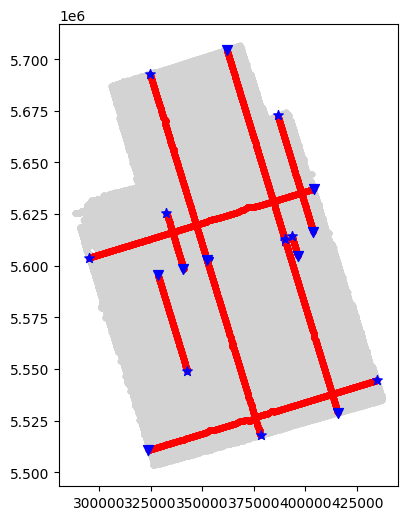

In [17]:
plot_selected_survey_line(selection:=["L10991", "L10120","L10830", "L10310", "L20310", "L20260", "L20830", "L21160", "T19110", "T29240"])

In [18]:
def plot_sharp_smooth(
    line_name: str,
    doi_true: bool = False,
    doi_shade: bool = False
):
    line_slice = line_slices[str(line_name)]
    line_df = smooth_df.iloc[line_slice]
    distances = pd.to_numeric(line_df["distance"], errors="coerce").to_numpy(dtype=float)
    dtm_line = pd.to_numeric(line_df["dtm"], errors="coerce").to_numpy(dtype=float)

    doi_true = bool(doi_true) if isinstance(doi_true, str) else doi_true
    doi_shade = bool(doi_shade) if isinstance(doi_shade, str) else doi_shade

    if doi_true | doi_shade:
        doi_alt = doi.iloc[line_slice]["DOI"]
        doi_alt_strict = doi_strict.iloc[line_slice]["DOI"]

    x_edges = _compute_cell_edges(distances)
    dtm_edges = _compute_cell_edges(dtm_line)
    X_edges = np.tile(x_edges[np.newaxis, :], (n_layer + 1, 1))
    Z_edges = dtm_edges[np.newaxis, :] - depth_edges[:, np.newaxis]

    _, ((ax1, _1, __1), (ax2, _2, __2)) = plt.subplots(
        2, 3, figsize = (20, 8), gridspec_kw = { "width_ratios": [8, 0.1, 1.9]}
        )

    section_smooth = smooth_inversion[line_slice, :].T.copy()
    section_sharp = sharp_inversion[line_slice, :].T.copy()

    if doi_true:
        ax1.plot(distances, doi_alt, color="k", linewidth=1.5, ls='--')
        ax2.plot(distances, doi_alt, color="k", linewidth=1.5, ls='--')
        ax1.plot(distances, doi_alt_strict, color="darkgrey", linewidth=1.5, ls='--')
        ax2.plot(distances, doi_alt_strict, color="darkgrey", linewidth=1.5, ls='--')

    if doi_shade:
        z_mask = Z_edges[:-1,:-1] < np.array(doi_alt)[np.newaxis,:]
        section_smooth[z_mask] = np.nan
        section_sharp[z_mask] = np.nan

    pcm = ax1.pcolormesh(
        X_edges,
        Z_edges,
        section_smooth,
        norm=LogNorm(vmin=8, vmax=60),
        shading="auto",
        cmap="turbo"
    )
    ax1.set_title("Smooth inversion", fontsize = 16)

    ax2.pcolormesh(
        X_edges,
        Z_edges,
        section_sharp,
        norm=LogNorm(vmin=8, vmax=60),
        shading="auto",
        cmap="turbo"
    )

    ax2.set_title("Sharp inversion", fontsize = 16)

    __1.scatter(smooth_df["x_wgs84"], smooth_df["y_wgs84"], c="lightgrey", s=10)
    __1.scatter(line_df["x_wgs84"], line_df["y_wgs84"], c="red", s=10)
    __1.scatter(line_df["x_wgs84"].iloc[0], line_df["y_wgs84"].iloc[0], c="white", s=100, label=f"{line_name} start", marker="*", edgecolors="black")
    # __1.scatter(line_df["x_wgs84"].iloc[-1], line_df["y_wgs84"].iloc[-1], c="blue", s=50, label=f"{line_name} end", marker="v")
    __1.set_aspect("equal")



    plt.colorbar(pcm, ax=_1, label="Resistivity (Ohm-m)",fraction=2.0)
    plt.tight_layout()

    _1.axis("off")
    _2.axis("off")
    __1.axis("off")
    __2.axis("off")

line_slider_xz = widgets.SelectionSlider(
    # options=np.sort(line_no),
    # value=np.sort(line_no)[0],
    options=np.sort(selection),
    value=np.sort(selection)[0],
    description="Line:",
    continuous_update=False,
)

doi_true_toggle = widgets.ToggleButton(
    value=False,
    description='DOI Line Toggle  ',
    disabled=False,
    button_style='info', # 'success', 'info', 'warning', 'danger' or ''
    tooltip='Description',
    icon='check' # (FontAwesome names without the `fa-` prefix)
)

doi_shade_toggle = widgets.ToggleButton(
    value=False,
    description='DOI Shade Toggle',
    disabled=False,
    button_style='info', # 'success', 'info', 'warning', 'danger' or ''
    tooltip='Description',
    icon='check' # (FontAwesome names without the `fa-` prefix)
)


xz_output = interactive_output(
    plot_sharp_smooth,
    {
        "line_name": line_slider_xz,
        "doi_true": doi_true_toggle,
        "doi_shade": doi_shade_toggle,
    },
)

VBox(
    [
        doi_true_toggle,
        doi_shade_toggle,
        line_slider_xz,
        xz_output,
    ]
)

In [19]:
def plot_reference(
    line_name
):
    line_slice = line_slices[str(line_name)]
    line_df = smooth_df.iloc[line_slice]
    distances = pd.to_numeric(line_df["distance"], errors="coerce").to_numpy(dtype=float)
    dtm_line = pd.to_numeric(line_df["dtm"], errors="coerce").to_numpy(dtype=float)
    doi_alt = doi.iloc[line_slice]["DOI"]
    doi_alt_strict = doi_strict.iloc[line_slice]["DOI"]

    x_edges = _compute_cell_edges(distances)
    dtm_edges = _compute_cell_edges(dtm_line)
    X_edges = np.tile(x_edges[np.newaxis, :], (n_layer + 1, 1))
    Z_edges = dtm_edges[np.newaxis, :] - depth_edges[:, np.newaxis]

    _, ((ax1, _1, __1), (ax2, _2, __2), (ax3, _3, __3)) = plt.subplots(
        3, 3, figsize = (20, 12), gridspec_kw = { "width_ratios": [8, 0.1, 1.9]}
        )

    section_mref0 = mref0_inversion[line_slice, :].T
    section_mref1 = mref1_inversion[line_slice, :].T

    pcm1 =ax1.pcolormesh(
        X_edges,
        Z_edges,
        section_mref0,
        norm=LogNorm(vmin=8, vmax=60),
        shading="auto",
        cmap="turbo"
    )
    ax1.plot(distances, doi_alt, color = "black", ls = "--", lw = 1.5)
    ax1.plot(distances, doi_alt_strict, color = "darkgrey", ls = "--", lw = 1.5)
    ax1.set_title("Inversion with 10 ohm-m reference", fontsize = 16)

    ax2.pcolormesh(
        X_edges,
        Z_edges,
        section_mref1,
        norm=LogNorm(vmin=8, vmax=60),
        shading="auto",
        cmap="turbo"
    )
    ax2.plot(distances, doi_alt, color = "black", ls = "--", lw = 1.5)
    ax2.plot(distances, doi_alt_strict, color = "darkgrey", ls = "--", lw = 1.5)
    ax2.set_title("Inversion with 30 ohm-m reference", fontsize = 16)

    pcm2 = ax3.pcolormesh(
        X_edges,
        Z_edges,
        np.abs(section_mref0 - section_mref1)/20,
        cmap="turbo",
        vmin=0,
        vmax=1
    )
    ax3.plot(distances, doi_alt, color = "white", ls = "--", lw = 1)
    ax3.plot(distances, doi_alt_strict, color = "darkgrey", ls = "--", lw = 1)
    ax3.set_title("DOI index", fontsize = 16)

    plt.colorbar(pcm1, ax=_1, label="Resistivity (Ohm-m)",fraction=2.0)
    plt.colorbar(pcm2, ax=_3, label="Index",fraction=2.0)
    plt.tight_layout()

    _1.axis("off")
    _2.axis("off")
    _3.axis("off")
    __1.axis("off")
    __2.axis("off")
    __3.axis("off")


line_slider_xz = widgets.SelectionSlider(
    # options=np.sort(line_no),
    # value=np.sort(line_no)[0],
    options=np.sort(selection),
    value=np.sort(selection)[0],
    description="Line:",
    continuous_update=False,
)

xz_output = interactive_output(
    plot_reference,
    {
        "line_name": line_slider_xz,
    },
)

VBox(
    [
        line_slider_xz,
        xz_output,
    ]
)

In [20]:
map_tree = KDTree(xy_model)
k_idw = min(k_nearest_points, len(xy_model))
map_distances, map_indices = map_tree.query(
    np.c_[X_map.ravel(), Y_map.ravel()], k=k_idw
)
if k_idw == 1:
    map_distances = map_distances[:, np.newaxis]
    map_indices = map_indices[:, np.newaxis]
outside_map = map_distances[:, 0] > max_distance


def plot_selected_XY(selected_depth):
    depth_index = int(np.argmin(np.abs(depth_centers - selected_depth)))
    values = np.mean(smooth_inversion[map_indices, depth_index], axis=1)
    values[outside_map] = np.nan

    fig, ax = plt.subplots(figsize=(12, 6))
    image = ax.pcolormesh(
        x_map, y_map, values.reshape(X_map.shape),
        cmap="turbo", norm=LogNorm(vmin=8, vmax=60), shading="auto",
    )
    ax.set_aspect("equal")
    ax.set_title(f"Smooth inversion at {depth_centers[depth_index]:.2f} m")
    fig.colorbar(image, ax=ax, label="Resistivity (Ohm-m)")


depth_slider_xz = widgets.SelectionSlider(
    options=depth_centers,
    value=depth_centers[0],
    description="Depth:",
    continuous_update=False,
)

map_output = interactive_output(
    plot_selected_XY,
    {"selected_depth": depth_slider_xz},
)

VBox([depth_slider_xz, map_output])

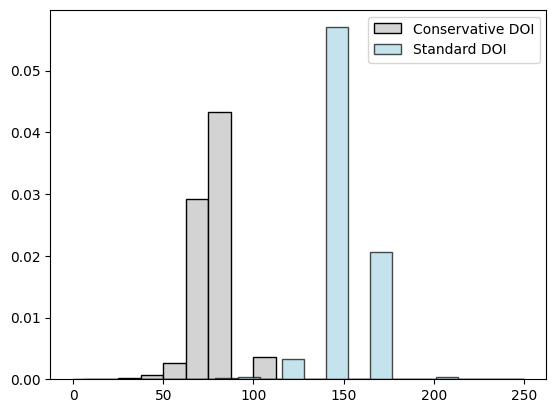

In [21]:
plt.hist(smooth_df["dtm"] - doi_strict["DOI"], bins=20, color="lightgrey", edgecolor="black", density=True)
plt.hist(sharp_df["dtm"] - doi["DOI"], bins=20, color="lightblue", edgecolor="black", alpha=0.7, density=True)
plt.legend(["Conservative DOI", "Standard DOI"], loc="upper right")

In [22]:
import gspy